In [ ]:
# ============================================================
# FL Fraud Detection Ultra V7.3
# Adaptive Fraud-Aware Federated Learning Framework
# ============================================================

!pip install -q imbalanced-learn openml seaborn matplotlib scikit-learn

# -------------------------------
# Imports
# -------------------------------

import os
import time
import copy
import random
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim


from torch.utils.data import (
    DataLoader,
    TensorDataset
)


from sklearn.datasets import fetch_openml

from sklearn.model_selection import (
    train_test_split
)

from sklearn.preprocessing import (
    StandardScaler
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    cohen_kappa_score,
    confusion_matrix,
    precision_recall_curve,
    roc_curve,
    brier_score_loss
)


from imblearn.over_sampling import SMOTE


warnings.filterwarnings("ignore")


# -------------------------------
# Device
# -------------------------------

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)


print("="*60)
print("FL Fraud Detection Ultra V7.3")
print("Device:", DEVICE)
print("="*60)

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 160.4/160.4 kB 17.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 93.8/93.8 kB 9.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 94.8 MB/s eta 0:00:00
FL Fraud Detection Ultra V7.3
Device: cuda


In [ ]:
# ============================================================
# Configuration V7.3
# ============================================================


CONFIG = {


    # Federated Setup
    "num_clients": 10,
    "global_rounds": 15,

    "local_epochs": 3,

    "batch_size": 256,


    # Optimization

    "learning_rate": 0.001,

    "weight_decay":1e-5,


    # Non IID

    "dirichlet_alpha":0.5,


    # FedProx

    "fedprox_mu":0.01,


    # Differential Privacy

    "dp_sigma":0.0001,

    "grad_clip":1.0,


    # Adaptive SMOTE

    "smote_ratio":0.2,

    "min_fraud_ratio":0.05,


    # Contrastive Learning

    "temperature":0.1,

    "supcon_weight":0.5,


    # Threshold Optimization

    "threshold_start":0.01,

    "threshold_end":0.99,

    "threshold_steps":99,


    # Adaptive Aggregation

    "sample_weight":0.5,

    "fraud_weight":0.3,

    "loss_weight":0.2,


    # Experiment

    "seeds":[42,2026,8888]

}



print(CONFIG)

{'num_clients': 10, 'global_rounds': 15, 'local_epochs': 3, 'batch_size': 256, 'learning_rate': 0.001, 'weight_decay': 1e-05, 'dirichlet_alpha': 0.5, 'fedprox_mu': 0.01, 'dp_sigma': 0.0001, 'grad_clip': 1.0, 'smote_ratio': 0.2, 'min_fraud_ratio': 0.05, 'temperature': 0.1, 'supcon_weight': 0.5, 'threshold_start': 0.01, 'threshold_end': 0.99, 'threshold_steps': 99, 'sample_weight': 0.5, 'fraud_weight': 0.3, 'loss_weight': 0.2, 'seeds': [42, 2026, 8888]}


In [ ]:
# ============================================================
# Dataset Loading
# Credit Card Fraud Dataset
# ============================================================


def load_dataset(seed):


    data = fetch_openml(
        data_id=1597,
        as_frame=True,
        parser="auto"
    )


    df = data.frame.copy()


    df["Class"] = (
        df["Class"]
        .astype(int)
    )


    X = df.drop(
        columns=["Class"]
    ).values


    y = df["Class"].values



    # -------------------------
    # Train / Validation / Test
    # -------------------------


    X_train, X_temp, y_train, y_temp = train_test_split(
        X,
        y,
        test_size=0.2,
        stratify=y,
        random_state=seed
    )


    X_val, X_test, y_val, y_test = train_test_split(
        X_temp,
        y_temp,
        test_size=0.5,
        stratify=y_temp,
        random_state=seed
    )


    # -------------------------
    # Leakage Free Scaling
    # -------------------------


    scaler = StandardScaler()


    X_train = scaler.fit_transform(
        X_train
    )


    X_val = scaler.transform(
        X_val
    )


    X_test = scaler.transform(
        X_test
    )



    return {

        "X_train":X_train,
        "y_train":y_train,

        "X_val":X_val,
        "y_val":y_val,

        "X_test":X_test,
        "y_test":y_test

    }

In [ ]:
# ============================================================
# Dirichlet Non-IID Client Split
# ============================================================


def create_federated_split(
        y,
        alpha,
        num_clients):


    client_indices = {
        i:[]
        for i in range(num_clients)
    }



    classes=np.unique(y)



    for cls in classes:


        cls_indices=np.where(
            y==cls
        )[0]


        np.random.shuffle(
            cls_indices
        )


        proportions=np.random.dirichlet(
            np.repeat(
                alpha,
                num_clients
            )
        )


        split_points=(
            np.cumsum(proportions)
            *
            len(cls_indices)
        ).astype(int)[:-1]



        splits=np.split(
            cls_indices,
            split_points
        )



        for i,idx in enumerate(splits):

            client_indices[i].extend(
                idx.tolist()
            )



    return client_indices

In [ ]:
# ============================================================
# Client Statistics
# ============================================================


def calculate_client_statistics(
        y,
        client_indices):


    stats=[]


    for cid,idx in client_indices.items():


        labels=y[idx]


        total=len(labels)


        fraud=np.sum(
            labels==1
        )


        ratio=fraud/total if total>0 else 0



        stats.append({

            "client":cid,

            "samples":total,

            "fraud":fraud,

            "fraud_ratio":ratio

        })



    return pd.DataFrame(stats)

In [ ]:
# ============================================================
# Adaptive SMOTE for Federated Clients
# ============================================================


def adaptive_smote_client(
        X_client,
        y_client,
        seed):


    fraud_ratio = np.mean(
        y_client == 1
    )


    fraud_count = np.sum(
        y_client == 1
    )



    # اگر عدم تعادل شدید باشد

    if (
        fraud_ratio < CONFIG["min_fraud_ratio"]
        and
        fraud_count > 2
    ):


        smote = SMOTE(

            sampling_strategy=
            CONFIG["smote_ratio"],

            random_state=seed,

            k_neighbors=
            min(
                5,
                fraud_count-1
            )
        )


        X_new,y_new = smote.fit_resample(
            X_client,
            y_client
        )


        return X_new,y_new,True



    return X_client,y_client,False

In [ ]:
# ============================================================
# Client DataLoaders
# ============================================================


def build_client_loaders(
        X_train,
        y_train,
        client_indices,
        seed):


    loaders=[]

    client_info=[]



    for cid,indices in client_indices.items():


        X_client = X_train[indices]

        y_client = y_train[indices]



        before=len(y_client)



        X_client,y_client,used_smote = (
            adaptive_smote_client(
                X_client,
                y_client,
                seed
            )
        )



        after=len(y_client)



        dataset = TensorDataset(

            torch.FloatTensor(X_client),

            torch.LongTensor(y_client)

        )



        loader = DataLoader(

            dataset,

            batch_size=
            CONFIG["batch_size"],

            shuffle=True

        )


        loaders.append(loader)



        client_info.append({

            "client":cid,

            "original_samples":before,

            "final_samples":after,

            "fraud":
            int(np.sum(y_client==1)),

            "smote":
            used_smote

        })



    return loaders,pd.DataFrame(client_info)

In [ ]:
# ============================================================
# V7.3 Fraud Neural Network
# ============================================================


class FraudNetV73(nn.Module):


    def __init__(
            self,
            input_dim):

        super().__init__()



        # Feature Encoder

        self.encoder = nn.Sequential(


            nn.Conv1d(
                1,
                32,
                kernel_size=3,
                padding=1
            ),


            nn.BatchNorm1d(
                32
            ),


            nn.ReLU(),



            nn.Conv1d(
                32,
                64,
                kernel_size=3,
                padding=1
            ),


            nn.BatchNorm1d(
                64
            ),


            nn.ReLU(),



            nn.AdaptiveAvgPool1d(
                1
            )

        )



        # Attention Layer


        self.attention = nn.MultiheadAttention(

            embed_dim=64,

            num_heads=4,

            batch_first=True

        )



        # Projection Head


        self.projector = nn.Sequential(

            nn.Linear(
                64,
                128
            ),

            nn.ReLU(),


            nn.Dropout(
                0.3
            ),


            nn.Linear(
                128,
                64
            )

        )



        # Fraud classifier


        self.classifier = nn.Linear(

            64,

            1

        )




    def forward(self,x):


        # [B,F]

        x=x.unsqueeze(1)


        # CNN

        x=self.encoder(x)


        # [B,64]

        x=x.squeeze(-1)



        # Attention expects sequence

        x=x.unsqueeze(1)



        x,_=self.attention(
            x,
            x,
            x
        )



        embedding=x.squeeze(1)



        z=self.projector(
            embedding
        )



        logits=self.classifier(

            F.relu(z)

        )



        return z,logits

In [ ]:
# ============================================================
# Model Information
# ============================================================


def model_information(model):


    params=sum(

        p.numel()

        for p in model.parameters()

    )


    trainable=sum(

        p.numel()

        for p in model.parameters()

        if p.requires_grad

    )


    size_mb = (

        params*4

        /

        (1024**2)

    )


    return {

        "Total Parameters":
        params,


        "Trainable Parameters":
        trainable,


        "Model Size MB":
        round(size_mb,4)

    }

In [ ]:
# ============================================================
# Focal Loss
# ============================================================


class FocalLoss(nn.Module):


    def __init__(
            self,
            alpha=0.75,
            gamma=2):

        super().__init__()

        self.alpha=alpha

        self.gamma=gamma



    def forward(
            self,
            logits,
            targets):


        bce = F.binary_cross_entropy_with_logits(

            logits,

            targets.float(),

            reduction="none"

        )



        pt=torch.exp(
            -bce
        )


        loss = (

            self.alpha

            *

            (1-pt)**self.gamma

            *

            bce

        )


        return loss.mean()

In [ ]:
# ============================================================
# Supervised Contrastive Loss
# ============================================================


class SupConLoss(nn.Module):


    def __init__(
            self,
            temperature=0.1):

        super().__init__()

        self.temperature=temperature



    def forward(
            self,
            features,
            labels):


        unique=torch.unique(labels)


        if len(unique)<2:

            return torch.tensor(

                0.0,

                device=features.device,

                requires_grad=True

            )



        features=F.normalize(

            features,

            dim=1

        )



        similarity=torch.matmul(

            features,

            features.T

        ) / self.temperature



        labels=labels.contiguous().view(-1,1)



        mask=torch.eq(

            labels,

            labels.T

        ).float()



        logits_mask=torch.ones_like(mask)

        logits_mask.fill_diagonal_(0)



        mask*=logits_mask



        exp_logits=torch.exp(

            similarity

        )*logits_mask



        log_prob=(

            similarity

            -

            torch.log(

                exp_logits.sum(
                    dim=1,
                    keepdim=True
                )

                +

                1e-9

            )

        )



        positives=mask.sum(1)



        valid=positives>0



        if valid.sum()==0:

            return torch.tensor(

                0.0,

                device=features.device,

                requires_grad=True

            )



        loss=(

            mask*log_prob

        ).sum(1)



        loss=loss[valid]/positives[valid]



        return -loss.mean()

In [ ]:
# ============================================================
# FedProx Loss
# ============================================================


def fedprox_loss(
        local_model,
        global_model):


    loss=0.0


    for lp,gp in zip(

        local_model.parameters(),

        global_model.parameters()

    ):


        loss += torch.sum(

            (lp-gp)**2

        )



    return (

        CONFIG["fedprox_mu"]

        /

        2

    )*loss

In [ ]:
# ============================================================
# Client Local Training
# V7.3
# ============================================================


def train_client_v73(
        local_model,
        global_model,
        dataloader):


    local_model.train()



    optimizer = optim.AdamW(

        local_model.parameters(),

        lr=CONFIG["learning_rate"],

        weight_decay=
        CONFIG["weight_decay"]

    )



    focal_loss = FocalLoss()

    supcon_loss = SupConLoss(
        CONFIG["temperature"]
    )



    epoch_losses=[]



    for epoch in range(
        CONFIG["local_epochs"]
    ):


        batch_losses=[]


        for X,y in dataloader:


            X=X.to(DEVICE)

            y=y.to(DEVICE)



            optimizer.zero_grad()



            embeddings, logits = (
                local_model(X)
            )



            loss_cls = focal_loss(

                logits.squeeze(),

                y

            )



            loss_con = supcon_loss(

                embeddings,

                y

            )



            loss_prox = fedprox_loss(

                local_model,

                global_model

            )



            total_loss=(

                loss_cls

                +

                CONFIG["supcon_weight"]

                *

                loss_con

                +

                loss_prox

            )



            total_loss.backward()



            # -------------------------
            # Differential Privacy Noise
            # -------------------------


            for param in local_model.parameters():


                if param.grad is not None:


                    noise=torch.normal(

                        mean=0,

                        std=CONFIG["dp_sigma"],

                        size=param.grad.shape,

                        device=param.grad.device

                    )


                    param.grad += noise



            torch.nn.utils.clip_grad_norm_(

                local_model.parameters(),

                CONFIG["grad_clip"]

            )



            optimizer.step()



            batch_losses.append(

                total_loss.item()

            )



        epoch_losses.append(

            np.mean(batch_losses)

        )



    return (

        copy.deepcopy(
            local_model.state_dict()
        ),

        np.mean(epoch_losses)

    )

In [ ]:
# ============================================================
# Adaptive Client Weight Calculation
# ============================================================


def calculate_client_weights(
        client_stats,
        client_losses):


    stats=client_stats.copy()



    # Normalize sample count


    samples = (

        stats["final_samples"]

        /

        stats["final_samples"].sum()

    )



    # Normalize fraud importance


    fraud = (

        stats["fraud"]

        /

        stats["fraud"].sum()

    )



    # Better local loss gets higher weight


    inv_loss = (

        1 /

        (
            np.array(client_losses)

            +

            1e-8

        )

    )


    inv_loss=(

        inv_loss

        /

        inv_loss.sum()

    )



    weights=(

        CONFIG["sample_weight"]

        *

        samples.values

        +

        CONFIG["fraud_weight"]

        *

        fraud.values

        +

        CONFIG["loss_weight"]

        *

        inv_loss

    )



    weights=(

        weights

        /

        weights.sum()

    )



    return weights

In [ ]:
# ============================================================
# Fraud-Aware Federated Aggregation
# ============================================================


def adaptive_fedavg_v73(
        global_model,
        client_weights,
        aggregation_weights):


    global_state = (
        global_model.state_dict()
    )



    for key in global_state.keys():


        stacked=torch.stack(

            [

            w[key].float()

            for w in client_weights

            ]

        )



        weight_tensor=torch.tensor(

            aggregation_weights,

            device=stacked.device

        )



        while len(
            weight_tensor.shape
        ) < len(stacked.shape):

            weight_tensor=weight_tensor.unsqueeze(-1)



        global_state[key]=(

            stacked

            *

            weight_tensor

        ).sum(0)



    global_model.load_state_dict(

        global_state

    )


    return global_model

In [ ]:
# ============================================================
# Validation Evaluation
# ============================================================


def evaluate_round(
        model,
        loader):


    model.eval()


    probs=[]

    labels=[]



    with torch.no_grad():


        for X,y in loader:


            X=X.to(DEVICE)


            _,logits=model(X)


            p=torch.sigmoid(

                logits

            )


            probs.extend(

                p.cpu().numpy().ravel()

            )


            labels.extend(

                y.numpy()

            )



    probs=np.array(probs)

    labels=np.array(labels)



    best_score=-1

    best_threshold=0.5



    for t in np.linspace(

        CONFIG["threshold_start"],

        CONFIG["threshold_end"],

        CONFIG["threshold_steps"]

    ):



        pred=(

            probs>=t

        )



        score=(

            0.5*

            recall_score(

                labels,

                pred,

                zero_division=0

            )

            +

            0.3*

            f1_score(

                labels,

                pred,

                zero_division=0

            )

            +

            0.2*

            precision_score(

                labels,

                pred,

                zero_division=0

            )

        )


        if score>best_score:

            best_score=score

            best_threshold=t



    pred=(

        probs>=best_threshold

    )


    return {


        "Accuracy":
        accuracy_score(labels,pred),


        "Precision":
        precision_score(labels,pred,zero_division=0),


        "Recall":
        recall_score(labels,pred,zero_division=0),


        "F1":
        f1_score(labels,pred,zero_division=0),


        "ROC_AUC":
        roc_auc_score(labels,probs),


        "PR_AUC":
        average_precision_score(labels,probs),


        "MCC":
        matthews_corrcoef(labels,pred),


        "Threshold":
        best_threshold,


        "Score":
        best_score

    }

In [ ]:
# ============================================================
# Validation / Test Loader
# ============================================================


def create_loader(
        X,
        y,
        shuffle=False):


    dataset = TensorDataset(

        torch.FloatTensor(X),

        torch.LongTensor(y)

    )


    return DataLoader(

        dataset,

        batch_size=
        CONFIG["batch_size"],

        shuffle=shuffle

    )

In [ ]:
# ============================================================
# Best Model Tracker
# ============================================================


class BestCheckpoint:


    def __init__(self):

        self.best_score=-1

        self.best_round=0

        self.best_state=None

        self.history=[]



    def update(
            self,
            model,
            metrics,
            round_id):


        score=metrics["Score"]


        self.history.append({

            "Round":round_id,

            **metrics

        })



        if score > self.best_score:


            self.best_score=score


            self.best_round=round_id


            self.best_state=copy.deepcopy(

                model.state_dict()

            )



            print(
                f" ⭐ New Best Model | "
                f"Round {round_id} | "
                f"Score={score:.4f}"
            )

In [ ]:
# ============================================================
# Communication Cost
# ============================================================


def communication_cost(
        model,
        rounds,
        clients):


    params=sum(

        p.numel()

        for p in model.parameters()

    )


    size_mb=(

        params*4

        /

        (1024**2)

    )


    total=(

        rounds

        *

        clients

        *

        2

        *

        size_mb

    )



    return {


        "Parameters":params,


        "Model_Size_MB":round(size_mb,4),


        "Communication_MB":round(total,4)

    }

In [ ]:
# ============================================================
# Full Federated Training V7.3
# ============================================================


def run_federated_experiment(seed):


    print("\n")
    print("="*70)
    print("SEED:",seed)
    print("="*70)



    start_time=time.time()



    # -------------------------
    # Load Dataset
    # -------------------------


    data=load_dataset(seed)


    X_train=data["X_train"]

    y_train=data["y_train"]


    X_val=data["X_val"]

    y_val=data["y_val"]


    X_test=data["X_test"]

    y_test=data["y_test"]



    # -------------------------
    # Federated Split
    # -------------------------


    client_indices=create_federated_split(

        y_train,

        CONFIG["dirichlet_alpha"],

        CONFIG["num_clients"]

    )



    client_loaders,client_info=build_client_loaders(

        X_train,

        y_train,

        client_indices,

        seed

    )



    print("\nClient Distribution")

    display(client_info)



    # -------------------------
    # Models
    # -------------------------


    global_model=FraudNetV73(

        X_train.shape[1]

    ).to(DEVICE)



    val_loader=create_loader(

        X_val,

        y_val

    )



    checkpoint=BestCheckpoint()



    round_history=[]



    # -------------------------
    # Federated Rounds
    # -------------------------


    for rnd in range(

        1,

        CONFIG["global_rounds"]+1

    ):


        round_start=time.time()


        client_weights=[]

        client_losses=[]



        print("\n")

        print(
            f"===== Round {rnd}/{CONFIG['global_rounds']} ====="
        )



        # Local Training


        for cid,loader in enumerate(client_loaders):


            local_model=FraudNetV73(

                X_train.shape[1]

            ).to(DEVICE)



            local_model.load_state_dict(

                global_model.state_dict()

            )



            weights,loss=train_client_v73(

                local_model,

                global_model,

                loader

            )



            client_weights.append(weights)


            client_losses.append(loss)



            print(

                f"Client {cid} | "
                f"Loss={loss:.4f}"

            )



        # Adaptive weights


        aggregation_weights=calculate_client_weights(

            client_info,

            client_losses

        )



        print(
            "\nAggregation weights:"
        )


        print(
            aggregation_weights
        )



        # Global update


        global_model=adaptive_fedavg_v73(

            global_model,

            client_weights,

            aggregation_weights

        )



        # Validation


        metrics=evaluate_round(

            global_model,

            val_loader

        )


        metrics["Round"]=rnd


        metrics["Round_Time"]=time.time()-round_start



        round_history.append(metrics)



        checkpoint.update(

            global_model,

            metrics,

            rnd

        )



        print(

            f"""

Round {rnd}

Recall :
{metrics['Recall']:.4f}

F1 :
{metrics['F1']:.4f}

PR-AUC :
{metrics['PR_AUC']:.4f}

Time :
{metrics['Round_Time']:.2f}s

"""

        )



    # -------------------------
    # Restore Best Model
    # -------------------------


    global_model.load_state_dict(

        checkpoint.best_state

    )



    total_time=time.time()-start_time



    system=communication_cost(

        global_model,

        CONFIG["global_rounds"],

        CONFIG["num_clients"]

    )



    return {


        "model":global_model,


        "history":pd.DataFrame(round_history),


        "checkpoint":checkpoint,


        "client_info":client_info,


        "system":system,


        "training_time":total_time,


        "test_data":(

            X_test,

            y_test

        )

    }

In [ ]:
# ============================================================
# Multi Seed Experiment
# ============================================================


experiments=[]


for seed in CONFIG["seeds"]:


    result=run_federated_experiment(seed)


    experiments.append(result)



SEED: 42

Client Distribution


,client,original_samples,final_samples,fraud,smote
0,0,77090,92386,15397,True
1,1,21253,21253,0,False
2,2,956,956,0,False
3,3,4320,4320,0,False
4,4,73658,88330,14721,True
5,5,12094,14491,2415,True
6,6,644,644,0,False
7,7,18025,18025,2,False
8,8,921,921,173,False
9,9,18884,22599,3766,True




===== Round 1/15 =====
Client 0 | Loss=2.6986
Client 1 | Loss=0.0137
Client 2 | Loss=0.0930
Client 3 | Loss=0.0349
Client 4 | Loss=2.6680
Client 5 | Loss=2.6862
Client 6 | Loss=0.1067
Client 7 | Loss=0.0940
Client 8 | Loss=2.7522
Client 9 | Loss=2.6603

Aggregation weights:
[0.30221619 0.14894374 0.01782975 0.05090541 0.28897839 0.04787096
 0.01518882 0.05000884 0.00370908 0.07434882]
 ⭐ New Best Model | Round 1 | Score=0.7176


Round 1

Recall :
0.8163

F1 :
0.6612

PR-AUC :
0.6292

Time :
47.06s




===== Round 2/15 =====
Client 0 | Loss=2.6467
Client 1 | Loss=0.0018
Client 2 | Loss=0.0057
Client 3 | Loss=0.0035
Client 4 | Loss=2.6189
Client 5 | Loss=2.6067
Client 6 | Loss=0.0068
Client 7 | Loss=0.0812
Client 8 | Loss=2.6273
Client 9 | Loss=2.5941

Aggregation weights:
[0.30172927 0.13350527 0.03195301 0.0568649  0.28848583 0.0473825
 0.02670094 0.0362896  0.00323339 0.07385528]
 ⭐ New Best Model | Round 2 | Score=0.7903


Round 2

Recall :
0.7959

F1 :
0.7879

PR-AUC :
0.6726

Tim

,client,original_samples,final_samples,fraud,smote
0,0,7424,8762,1460,True
1,1,6243,7384,1230,True
2,2,35021,35021,0,False
3,3,370,370,0,False
4,4,34196,41008,6834,True
5,5,21070,25222,4203,True
6,6,37263,44688,7448,True
7,7,8043,9616,1602,True
8,8,4150,4150,2,False
9,9,74065,88810,14801,True




===== Round 1/15 =====
Client 0 | Loss=2.7459
Client 1 | Loss=2.7593
Client 2 | Loss=0.0105
Client 3 | Loss=0.1028
Client 4 | Loss=2.6483
Client 5 | Loss=2.6749
Client 6 | Loss=2.6780
Client 7 | Loss=2.7199
Client 8 | Loss=0.3644
Client 9 | Loss=2.6507

Aggregation weights:
[0.02884748 0.02440846 0.2386722  0.01838496 0.13260674 0.0818153
 0.14444325 0.0315985  0.01283477 0.28638834]
 ⭐ New Best Model | Round 1 | Score=0.6578


Round 1

Recall :
0.6531

F1 :
0.6598

PR-AUC :
0.5740

Time :
38.41s




===== Round 2/15 =====
Client 0 | Loss=2.6778
Client 1 | Loss=2.6942
Client 2 | Loss=0.0025
Client 3 | Loss=0.0211
Client 4 | Loss=2.5951
Client 5 | Loss=2.6159
Client 6 | Loss=2.6215
Client 7 | Loss=2.6360
Client 8 | Loss=0.3335
Client 9 | Loss=2.6032

Aggregation weights:
[0.02835036 0.02391358 0.24258509 0.0216823  0.13209049 0.08130453
 0.14393291 0.0310977  0.00917085 0.28587219]
 ⭐ New Best Model | Round 2 | Score=0.7494


Round 2

Recall :
0.8163

F1 :
0.7143

PR-AUC :
0.6864

Tim

,client,original_samples,final_samples,fraud,smote
0,0,17362,20821,3470,True
1,1,67835,81265,13544,True
2,2,45126,54036,9006,True
3,3,79166,94951,15825,True
4,4,2591,3058,509,True
5,5,28,28,17,False
6,6,5552,6639,1106,True
7,7,7563,9067,1511,True
8,8,265,265,14,False
9,9,2357,2787,464,True




===== Round 1/15 =====
Client 0 | Loss=2.5903
Client 1 | Loss=2.7038
Client 2 | Loss=2.7152
Client 3 | Loss=2.6384
Client 4 | Loss=2.7556
Client 5 | Loss=1.8093
Client 6 | Loss=2.7078
Client 7 | Loss=2.6299
Client 8 | Loss=2.0054
Client 9 | Loss=2.7450

Aggregation weights:
[0.08019408 0.25659923 0.17669336 0.29717843 0.02696522 0.02758336
 0.03778265 0.04544595 0.02531642 0.02624129]
 ⭐ New Best Model | Round 1 | Score=0.5869


Round 1

Recall :
0.6735

F1 :
0.5366

PR-AUC :
0.5246

Time :
40.77s




===== Round 2/15 =====
Client 0 | Loss=2.5474
Client 1 | Loss=2.6534
Client 2 | Loss=2.6583
Client 3 | Loss=2.5882
Client 4 | Loss=2.6091
Client 5 | Loss=1.9551
Client 6 | Loss=2.6202
Client 7 | Loss=2.5597
Client 8 | Loss=1.5450
Client 9 | Loss=2.6304

Aggregation weights:
[0.0796178  0.25608413 0.17622278 0.2966577  0.02709787 0.0243674
 0.03752102 0.04506848 0.03120528 0.02615755]
 ⭐ New Best Model | Round 2 | Score=0.7304


Round 2

Recall :
0.7143

F1 :
0.7368

PR-AUC :
0.6621

Tim

In [ ]:
# ============================================================
# Final Test Evaluation
# ============================================================


def final_test_evaluation(
        model,
        X_test,
        y_test,
        threshold):


    model.eval()


    loader=create_loader(
        X_test,
        y_test
    )


    probs=[]

    labels=[]



    with torch.no_grad():


        for X,y in loader:


            X=X.to(DEVICE)


            _,logits=model(X)


            p=torch.sigmoid(
                logits
            )


            probs.extend(
                p.cpu().numpy().ravel()
            )


            labels.extend(
                y.numpy()
            )



    probs=np.array(probs)

    labels=np.array(labels)



    pred=(

        probs>=threshold

    )



    tn,fp,fn,tp=confusion_matrix(

        labels,

        pred

    ).ravel()



    specificity=(

        tn/(tn+fp)

    )


    sensitivity=(

        tp/(tp+fn)

    )


    npv=(

        tn/(tn+fn)

    )



    fpr=(

        fp/(fp+tn)

    )


    fnr=(

        fn/(fn+tp)

    )


    fdr=(

        fp/(fp+tp)

    )



    return {


        "Accuracy":

        accuracy_score(

            labels,

            pred

        ),


        "Precision":

        precision_score(

            labels,

            pred,

            zero_division=0

        ),


        "Recall":

        sensitivity,


        "Specificity":

        specificity,


        "F1":

        f1_score(

            labels,

            pred,

            zero_division=0

        ),


        "F2":

        fbeta_score(

            labels,

            pred,

            beta=2,

            zero_division=0

        ),



        "Balanced_Accuracy":

        balanced_accuracy_score(

            labels,

            pred

        ),



        "MCC":

        matthews_corrcoef(

            labels,

            pred

        ),



        "Cohen_Kappa":

        cohen_kappa_score(

            labels,

            pred

        ),



        "ROC_AUC":

        roc_auc_score(

            labels,

            probs

        ),



        "PR_AUC":

        average_precision_score(

            labels,

            probs

        ),



        "NPV":

        npv,


        "FPR":

        fpr,


        "FNR":

        fnr,


        "FDR":

        fdr,


        "Brier":

        brier_score_loss(

            labels,

            probs

        ),



        "Threshold":

        threshold,


        "Confusion_Matrix":

        [

            [tn,fp],

            [fn,tp]

        ],



        "Probabilities":

        probs,


        "Labels":

        labels

    }

In [ ]:
# ============================================================
# Evaluate All Seeds
# ============================================================


final_results=[]


for exp,seed in zip(
        experiments,
        CONFIG["seeds"]):


    best_threshold=(

        exp["checkpoint"]

        .history[

            exp["checkpoint"].best_round-1

        ]

        ["Threshold"]

    )



    result=final_test_evaluation(

        exp["model"],

        exp["test_data"][0],

        exp["test_data"][1],

        best_threshold

    )



    result["Seed"]=seed


    result["Best_Round"]=(
        exp["checkpoint"].best_round
    )


    result["Training_Time_sec"]=(
        exp["training_time"]
    )


    result.update(
        exp["system"]
    )


    final_results.append(
        result
    )



final_df=pd.DataFrame(
    final_results
)


display(
    final_df.drop(
        columns=[
            "Confusion_Matrix",
            "Probabilities",
            "Labels"
        ]
    )
)

,Accuracy,Precision,Recall,Specificity,F1,F2,Balanced_Accuracy,MCC,Cohen_Kappa,ROC_AUC,...,FNR,FDR,Brier,Threshold,Seed,Best_Round,Training_Time_sec,Parameters,Model_Size_MB,Communication_MB
0,0.999052,0.689655,0.816327,0.999367,0.747664,0.787402,0.907847,0.749859,0.747192,0.940426,...,0.183673,0.310345,0.009607,0.37,42,2,619.552279,39809,0.1519,45.5578
1,0.998736,0.603175,0.775510,0.999121,0.678571,0.733591,0.887315,0.683329,0.677948,0.939665,...,0.224490,0.396825,0.003323,0.41,2026,7,589.150932,39809,0.1519,45.5578
2,0.999368,0.860465,0.755102,0.999789,0.804348,0.774059,0.877446,0.805754,0.804033,0.942288,...,0.244898,0.139535,0.000738,0.30,8888,14,622.899233,39809,0.1519,45.5578


In [ ]:
# ============================================================
# Mean +/- STD Reporting
# ============================================================


metric_columns=[

"Accuracy",

"Precision",

"Recall",

"Specificity",

"F1",

"F2",

"Balanced_Accuracy",

"MCC",

"Cohen_Kappa",

"ROC_AUC",

"PR_AUC",

"NPV",

"FPR",

"FNR",

"FDR",

"Brier"

]



mean_table=pd.DataFrame({

    "Mean":

    final_df[metric_columns].mean(),


    "STD":

    final_df[metric_columns].std()

})



mean_table

,Mean,STD
Accuracy,0.999052,0.000316
Precision,0.717765,0.130928
Recall,0.782313,0.031174
Specificity,0.999426,0.000338
F1,0.743528,0.062990
F2,0.765017,0.028022
Balanced_Accuracy,0.890869,0.015509
MCC,0.746314,0.061289
Cohen_Kappa,0.743058,0.063144
ROC_AUC,0.940793,0.001349


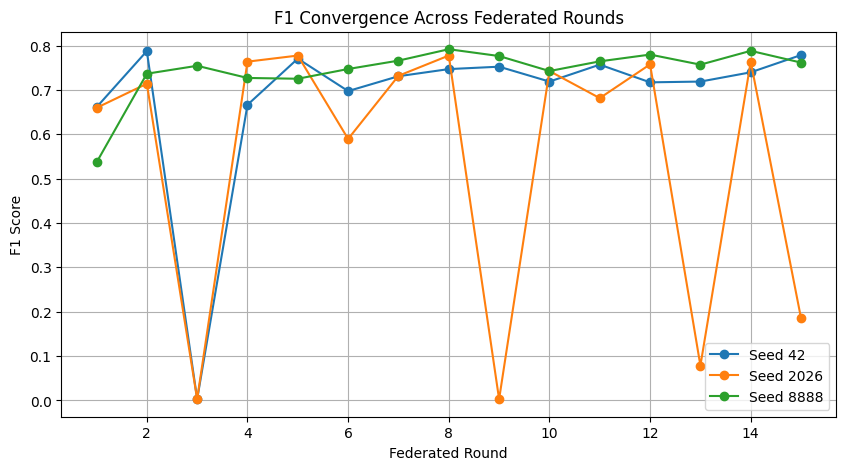

In [ ]:
# ============================================================
# Round F1 Evolution
# ============================================================


plt.figure(
    figsize=(10,5)
)


for exp,seed in zip(
    experiments,
    CONFIG["seeds"]):


    plt.plot(

        exp["history"]["Round"],

        exp["history"]["F1"],

        marker="o",

        label=f"Seed {seed}"

    )



plt.xlabel("Federated Round")

plt.ylabel("F1 Score")

plt.title(
    "F1 Convergence Across Federated Rounds"
)

plt.grid()

plt.legend()

plt.show()

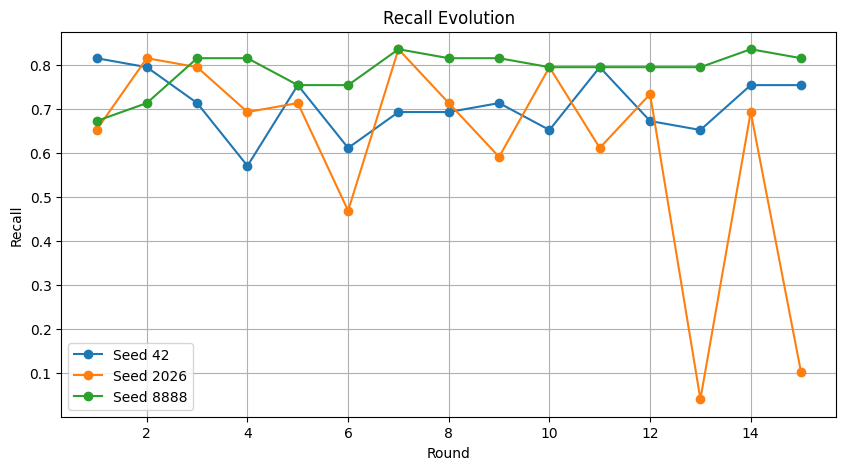

In [ ]:
plt.figure(
    figsize=(10,5)
)


for exp,seed in zip(
    experiments,
    CONFIG["seeds"]):


    plt.plot(

        exp["history"]["Round"],

        exp["history"]["Recall"],

        marker="o",

        label=f"Seed {seed}"

    )


plt.title(
    "Recall Evolution"
)


plt.xlabel(
    "Round"
)


plt.ylabel(
    "Recall"
)


plt.grid()

plt.legend()

plt.show()

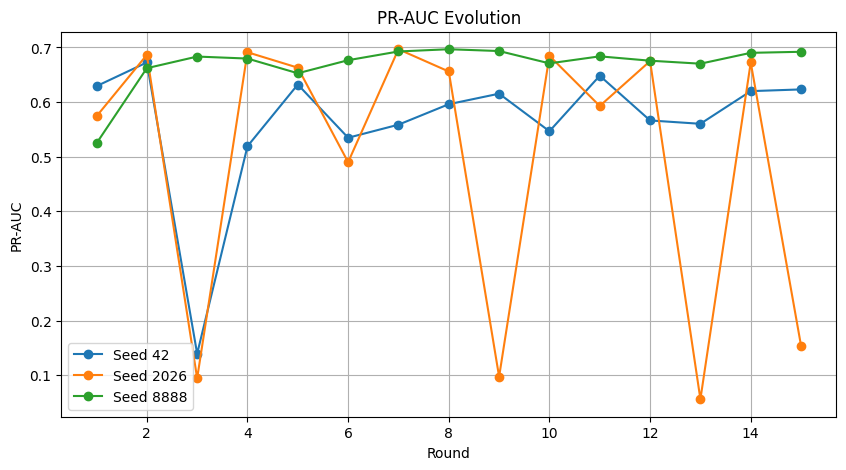

In [ ]:
plt.figure(
    figsize=(10,5)
)


for exp,seed in zip(
    experiments,
    CONFIG["seeds"]):


    plt.plot(

        exp["history"]["Round"],

        exp["history"]["PR_AUC"],

        marker="o",

        label=f"Seed {seed}"

    )


plt.title(
    "PR-AUC Evolution"
)


plt.xlabel(
    "Round"
)


plt.ylabel(
    "PR-AUC"
)


plt.grid()

plt.legend()

plt.show()

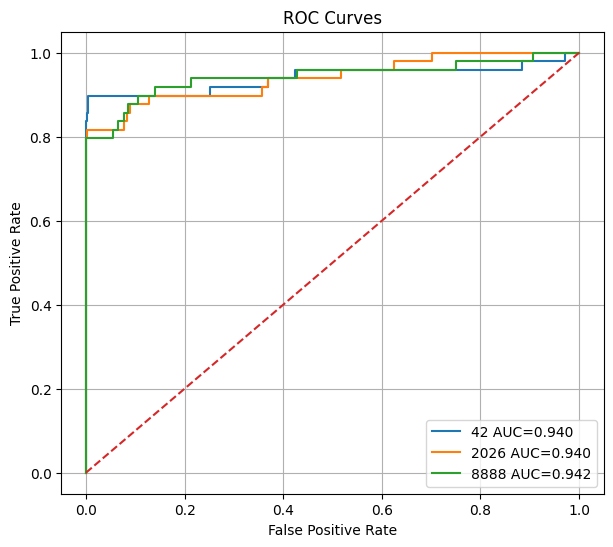

In [ ]:
# ============================================================
# ROC Curves
# ============================================================


plt.figure(
    figsize=(7,6)
)


for result in final_results:


    fpr,tpr,_=roc_curve(

        result["Labels"],

        result["Probabilities"]

    )


    auc_value=roc_auc_score(

        result["Labels"],

        result["Probabilities"]

    )


    plt.plot(

        fpr,

        tpr,

        label=f"{result['Seed']} AUC={auc_value:.3f}"

    )



plt.plot(

    [0,1],

    [0,1],

    "--"

)


plt.xlabel(
    "False Positive Rate"
)


plt.ylabel(
    "True Positive Rate"
)


plt.title(
    "ROC Curves"
)


plt.legend()

plt.grid()

plt.show()

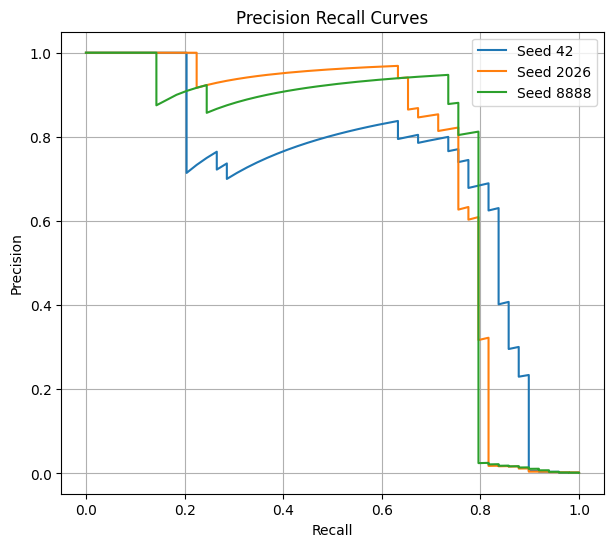

In [ ]:
plt.figure(
    figsize=(7,6)
)


for result in final_results:


    precision,recall,_=precision_recall_curve(

        result["Labels"],

        result["Probabilities"]

    )


    plt.plot(

        recall,

        precision,

        label=f"Seed {result['Seed']}"

    )



plt.xlabel(
    "Recall"
)


plt.ylabel(
    "Precision"
)


plt.title(
    "Precision Recall Curves"
)


plt.legend()

plt.grid()

plt.show()

In [ ]:
# ============================================================
# Best Seed Selection
# ============================================================


best_index = np.argmax(
    final_df["F1"]
)


best_result = final_results[
    best_index
]


best_cm = np.array(
    best_result["Confusion_Matrix"]
)


print(
    "Best Seed:",
    best_result["Seed"]
)

print(
    "Best Round:",
    best_result["Best_Round"]
)

print(
    best_cm
)

Best Seed: 8888
Best Round: 14
[[28426     6]
 [   12    37]]


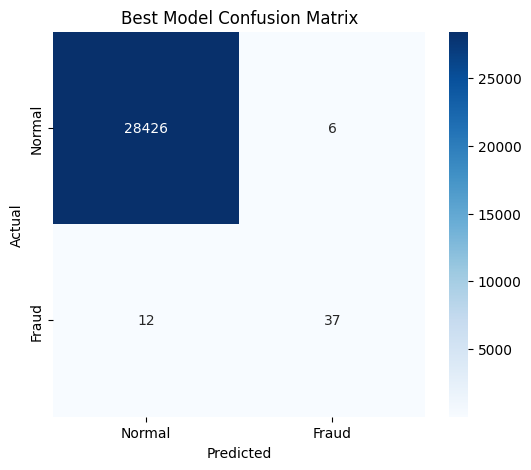

In [ ]:
# ============================================================
# Confusion Matrix Plot
# ============================================================


plt.figure(
    figsize=(6,5)
)


sns.heatmap(

    best_cm,

    annot=True,

    fmt="d",

    cmap="Blues",

    xticklabels=[
        "Normal",
        "Fraud"
    ],

    yticklabels=[
        "Normal",
        "Fraud"
    ]

)


plt.xlabel(
    "Predicted"
)


plt.ylabel(
    "Actual"
)


plt.title(
    "Best Model Confusion Matrix"
)


plt.show()

In [ ]:
# ============================================================
# Expected Calibration Error
# ============================================================


def calculate_ece(
        y_true,
        y_prob,
        bins=10):


    bin_edges=np.linspace(
        0,
        1,
        bins+1
    )


    ece=0


    for i in range(bins):


        mask=(

            y_prob>=bin_edges[i]

        ) & (

            y_prob<bin_edges[i+1]

        )


        if np.sum(mask)>0:


            confidence=np.mean(
                y_prob[mask]
            )


            accuracy=np.mean(
                y_true[mask]
            )


            ece += (

                np.abs(
                    confidence-accuracy
                )

                *

                np.mean(mask)

            )


    return ece

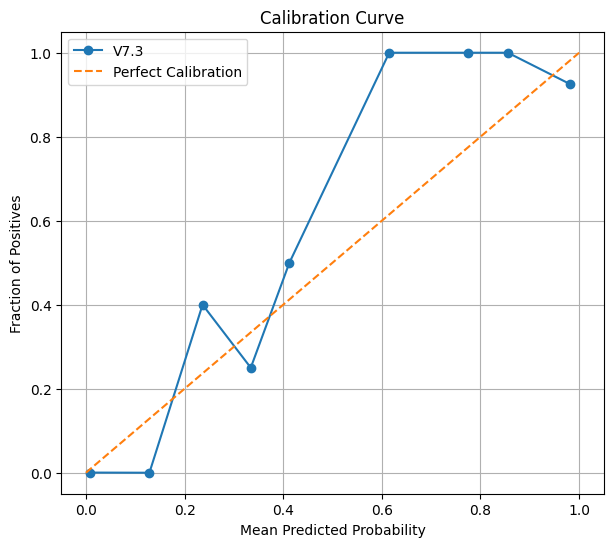

ECE: 0.00829045522172853
Brier Score: 0.0007378645231195748


In [ ]:
from sklearn.calibration import calibration_curve


# Best model probability

y_true=best_result["Labels"]

y_prob=best_result["Probabilities"]



fraction_of_positives,mean_predicted_value = calibration_curve(

    y_true,

    y_prob,

    n_bins=10

)



plt.figure(
    figsize=(7,6)
)


plt.plot(

    mean_predicted_value,

    fraction_of_positives,

    marker="o",

    label="V7.3"

)


plt.plot(

    [0,1],

    [0,1],

    "--",

    label="Perfect Calibration"

)



plt.xlabel(
    "Mean Predicted Probability"
)


plt.ylabel(
    "Fraction of Positives"
)


plt.title(
    "Calibration Curve"
)


plt.legend()

plt.grid()

plt.show()



ece=calculate_ece(
    y_true,
    y_prob
)


print(
    "ECE:",
    ece
)


print(
    "Brier Score:",
    brier_score_loss(
        y_true,
        y_prob
    )
)

In [ ]:
# ============================================================
# Client Distribution Visualization
# ============================================================


best_exp = experiments[best_index]


client_df = best_exp[
    "client_info"
]


display(
    client_df
)

,client,original_samples,final_samples,fraud,smote
0,0,17362,20821,3470,True
1,1,67835,81265,13544,True
2,2,45126,54036,9006,True
3,3,79166,94951,15825,True
4,4,2591,3058,509,True
5,5,28,28,17,False
6,6,5552,6639,1106,True
7,7,7563,9067,1511,True
8,8,265,265,14,False
9,9,2357,2787,464,True


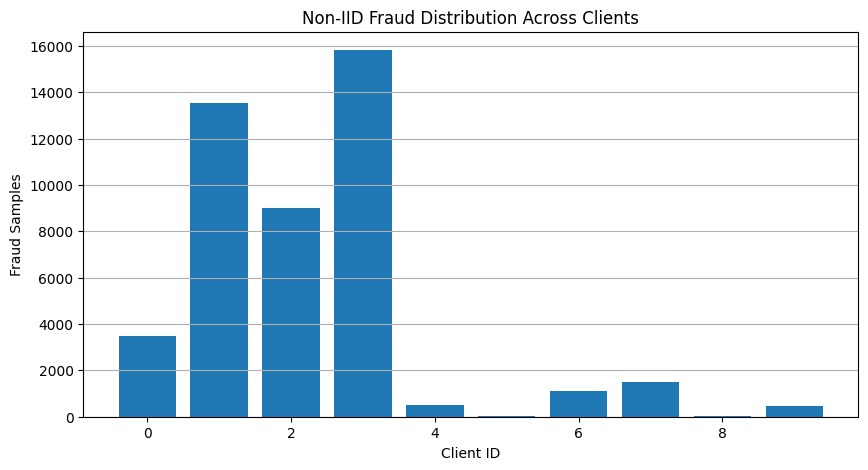

In [ ]:
plt.figure(
    figsize=(10,5)
)


plt.bar(

    client_df["client"],

    client_df["fraud"]

)


plt.xlabel(
    "Client ID"
)


plt.ylabel(
    "Fraud Samples"
)


plt.title(
    "Non-IID Fraud Distribution Across Clients"
)


plt.grid(
    axis="y"
)


plt.show()

In [ ]:
# ============================================================
# Aggregation Weight Plot
# ============================================================


aggregation_df=pd.DataFrame({

    "Client":

    client_df["client"],


    "Weight":

    calculate_client_weights(

        client_df,

        np.ones(
            len(client_df)
        )

    )

})


display(
    aggregation_df
)

,Client,Weight
0,0,0.081042
1,1,0.258250
2,2,0.178422
3,3,0.298375
4,4,0.028961
5,5,0.020163
6,6,0.039461
7,7,0.046581
8,8,0.020578
9,9,0.028168


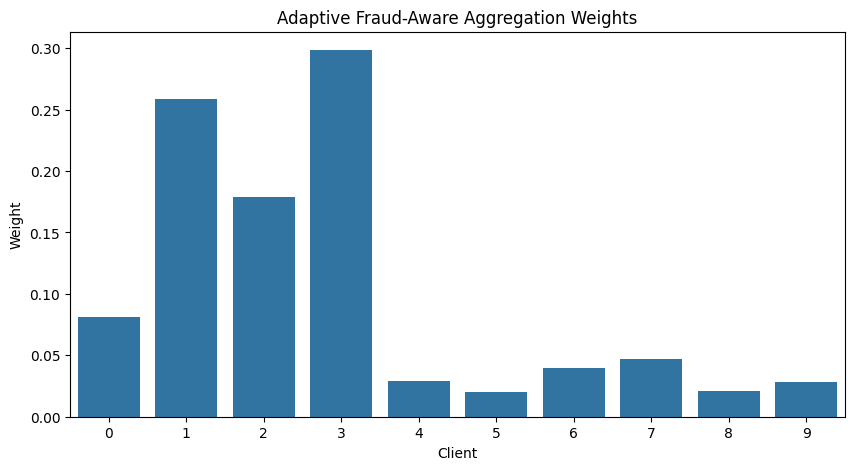

In [ ]:
plt.figure(
    figsize=(10,5)
)


sns.barplot(

    data=aggregation_df,

    x="Client",

    y="Weight"

)


plt.title(
    "Adaptive Fraud-Aware Aggregation Weights"
)


plt.show()

In [ ]:
# ============================================================
# Communication Report
# ============================================================


communication_report=pd.DataFrame({

    "Metric":[

        "Parameters",

        "Model Size MB",

        "Total Communication MB",

        "Communication/Round MB"

    ],


    "Value":[

        best_exp["system"]["Parameters"],


        best_exp["system"]["Model_Size_MB"],


        best_exp["system"]["Communication_MB"],


        best_exp["system"]["Communication_MB"]

        /

        CONFIG["global_rounds"]

    ]

})


communication_report

,Metric,Value
0,Parameters,39809.000000
1,Model Size MB,0.151900
2,Total Communication MB,45.557800
3,Communication/Round MB,3.037187


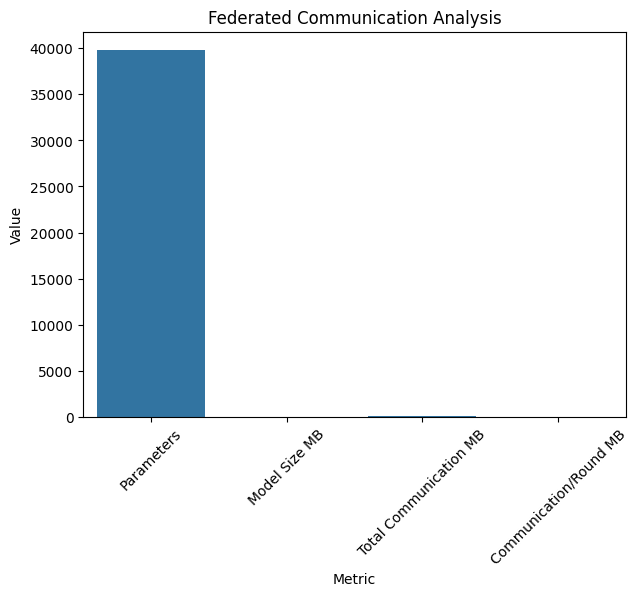

In [ ]:
plt.figure(
    figsize=(7,5)
)


sns.barplot(

    data=communication_report,

    x="Metric",

    y="Value"

)


plt.xticks(
    rotation=45
)


plt.title(
    "Federated Communication Analysis"
)


plt.show()

In [ ]:
# ============================================================
# Training Time Report
# ============================================================


time_report=pd.DataFrame({

    "Seed":

    final_df["Seed"],


    "Training Time(sec)":

    final_df["Training_Time_sec"],


    "Best Round":

    final_df["Best_Round"]

})


time_report

,Seed,Training Time(sec),Best Round
0,42,619.552279,2
1,2026,589.150932,7
2,8888,622.899233,14


In [ ]:
# ============================================================
# Export Results
# ============================================================


final_df.to_csv(
    "V7_3_Final_Metrics.csv",
    index=False
)


mean_table.to_csv(
    "V7_3_Mean_STD.csv"
)


client_df.to_csv(
    "V7_3_Client_Distribution.csv",
    index=False
)


communication_report.to_csv(
    "V7_3_Communication_Report.csv",
    index=False
)


time_report.to_csv(
    "V7_3_Training_Time.csv",
    index=False
)


print(
    "All Results Exported Successfully"
)

All Results Exported Successfully
